
# Medical Insurance Cost Prediction

## Goal

Build Machine Learning models to predict individual medical insurance charges based on customer characteristics.

## Audience and purpose

This project is for learning and understanding how Machine Learning can be used to make predictions from real world data, It builds on the previous Medical Insurance Charges Analysis project, moving from exploring historical patterns to predicting charges for unseen customers.

## Prediction task

- Learning type: Supervised Learning
- Problem type: Regression
- Input features (X): age, sex, bmi, children, smoker, region
- Target variable (y): charges

## Questions

- Can customer characteristics be used to predict medical insurance charges ?
- How accurately can Machine Learning models predict these charges ?
- Which Regression models perform best on unseen data ?
- Which features are most useful for making predictions ?

This project focuses on prediction, not proving cause and effect, Model predictions are estimates based on historical data, not actual insurance quotations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/abdel/Desktop/ML roadmap/Medical-Insurance/Data/insurance.csv")

### 1 - Cleaning data

In [3]:
null_values = df.isnull().sum().sum()
print("Number of null values : ", null_values)

Number of null values :  0


In [4]:
df = df.drop_duplicates().reset_index(drop=True)
df.duplicated().any()

np.False_

### 2 - Define Features and Target

In [5]:
X = df.drop(columns=["charges"])
y = df["charges"]

In [6]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1337, 6)
Target shape: (1337,)


### 3 - Train-Test Split

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

In [9]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (1069, 6)
Testing features: (268, 6)


In [10]:
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training target: (1069,)
Testing target: (268,)


### 4 - Data Preprocessing

#### 4.1 - Feature Types Inspection

In [11]:
print(X_train.dtypes)

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
dtype: object


In [12]:
X_train.columns.to_list()

['age', 'sex', 'bmi', 'children', 'smoker', 'region']

In [13]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

In [14]:
print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['age', 'bmi', 'children']
Categorical features: ['sex', 'smoker', 'region']


#### 4.2 - Encoding and Scaling

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [17]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [18]:
feature_names = preprocessor.get_feature_names_out()

In [19]:
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("\nProcessed feature names:\n", feature_names)


Training shape: (1069, 8)
Testing shape: (268, 8)

Processed feature names:
 ['num__age' 'num__bmi' 'num__children' 'cat__sex_male' 'cat__smoker_yes'
 'cat__region_northwest' 'cat__region_southeast' 'cat__region_southwest']



#### 4.3 - Verify Preprocessing

In [20]:
X_train_processed_df = pd.DataFrame( X_train_processed, columns=feature_names, index=X_train.index )

In [21]:
X_train_processed_df.head()

,num__age,num__bmi,num__children,cat__sex_male,cat__smoker_yes,cat__region_northwest,cat__region_southeast,cat__region_southwest
1113,-1.157680,-0.996928,-0.907908,1.0,0.0,0.0,0.0,0.0
967,-1.300619,-0.792762,0.766904,1.0,0.0,0.0,0.0,0.0
598,0.914926,1.154664,0.766904,0.0,0.0,1.0,0.0,0.0
170,1.701087,1.806837,-0.907908,1.0,0.0,0.0,1.0,0.0
275,0.557580,-0.651417,0.766904,0.0,0.0,0.0,0.0,0.0


In [22]:
print("Numerical feature means:")
print(X_train_processed_df[["num__age", "num__bmi", "num__children"]].mean().round(3))

Numerical feature means:
num__age         0.0
num__bmi         0.0
num__children    0.0
dtype: float64


In [23]:
print("\nNumerical feature standard deviations:")
print(X_train_processed_df[["num__age", "num__bmi", "num__children"]].std(ddof=0).round(3))


Numerical feature standard deviations:
num__age         1.0
num__bmi         1.0
num__children    1.0
dtype: float64


* Its Standard Scalled.  

### 5 - Baseline Model

In [24]:
from sklearn.dummy import DummyRegressor

In [25]:
baseline_model = DummyRegressor(strategy="mean")    # baseline model

In [26]:
baseline_model.fit(X_train_processed, y_train)      # Train the model

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None


In [27]:
y_pred_baseline = baseline_model.predict(X_test_processed)    # Generate predictions on test data

In [28]:
print("Baseline prediction:", y_pred_baseline[0])
print("First 5 predictions:", y_pred_baseline[:3])

Baseline prediction: 13030.203369289055
First 5 predictions: [13030.20336929 13030.20336929 13030.20336929]


#### 5.1 - Baseline Evaluation

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [30]:
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_mse = mean_squared_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, y_pred_baseline)

In [31]:
print(f"Baseline MAE:  ${baseline_mae:.2f}")
print(f"Baseline MSE:  {baseline_mse:.2f}")
print(f"Baseline RMSE: ${baseline_rmse:.2f}")
print(f"Baseline R²:   {baseline_r2:.4f}")

Baseline MAE:  $9861.80
Baseline MSE:  185298141.69
Baseline RMSE: $13612.43
Baseline R²:   -0.0084


### 6 - Linear Regression

In [32]:
from sklearn.linear_model import LinearRegression

In [33]:
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)
y_pred_linear = linear_model.predict(X_test_processed)

In [34]:
print("Bias (Intercept):", linear_model.intercept_)

Bias (Intercept): 8947.95219506918


In [35]:
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Weight": linear_model.coef_
})

coefficients.sort_values( by="Weight", key=abs, ascending=False )

,Feature,Weight
4,cat__smoker_yes,23077.764593
0,num__age,3472.975553
1,num__bmi,1927.828251
6,cat__region_southeast,-838.919616
7,cat__region_southwest,-659.139752
2,num__children,636.501185
5,cat__region_northwest,-391.761455
3,cat__sex_male,-101.542054


In [36]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_linear,
    "Loss": np.abs(y_test - y_pred_linear).round(1)
})

comparison.sort_values(by="Loss", ascending=False).head()

,Actual,Predicted,Loss
543,63770.42801,39659.206889,24111.2
818,55135.40209,31107.766807,24027.6
1229,60021.39897,36988.215397,23033.2
986,28340.18885,9028.579983,19311.6
115,30259.99556,12811.716568,17448.3


#### 6.1 - Linear Regression Evaluation

* Compare its performance with the baseline model to determine

In [37]:
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, y_pred_linear)

In [38]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae],
    "MSE": [baseline_mse, linear_mse],
    "RMSE": [baseline_rmse, linear_rmse],
    "R2": [baseline_r2, linear_r2]
})

In [39]:
model_comparison.round(4)

,Model,MAE,MSE,RMSE,R2
0,Baseline,9861.7979,1.852981e+08,13612.4260,-0.0084
1,Linear Regression,4177.0456,3.547802e+07,5956.3429,0.8069


- **MAE** decreased by approximately **57.6%**.
- **RMSE** decreased by approximately **56.2%**.
- **R²** improved to **0.8069** from a negative value, meaning the model explains approximately **80.69%** of the variance in the charges values within the test data.

#### 6.2 Residual Analysis

Analyze the differences between actual and predicted insurance charges to identify prediction patterns and potential model limitations.

In [40]:
residuals = y_test - y_pred_linear

In [41]:
residuals_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_linear,
    "Residual": residuals
})

residuals_df.head()

,Actual,Predicted,Residual
899,8688.85885,8143.693884,545.164966
1063,5708.86700,5737.115683,-28.248683
1255,11436.73815,14369.314876,-2932.576726
298,38746.35510,31745.513636,7000.841464
237,4463.20510,8962.386657,-4499.181557


In [42]:
print("Mean Residual:", residuals.mean())
print("Minimum Residual:", residuals.min())
print("Maximum Residual:", residuals.max())

Mean Residual: 425.2569948432542
Minimum Residual: -10314.509078071678
Maximum Residual: 24111.221121119786


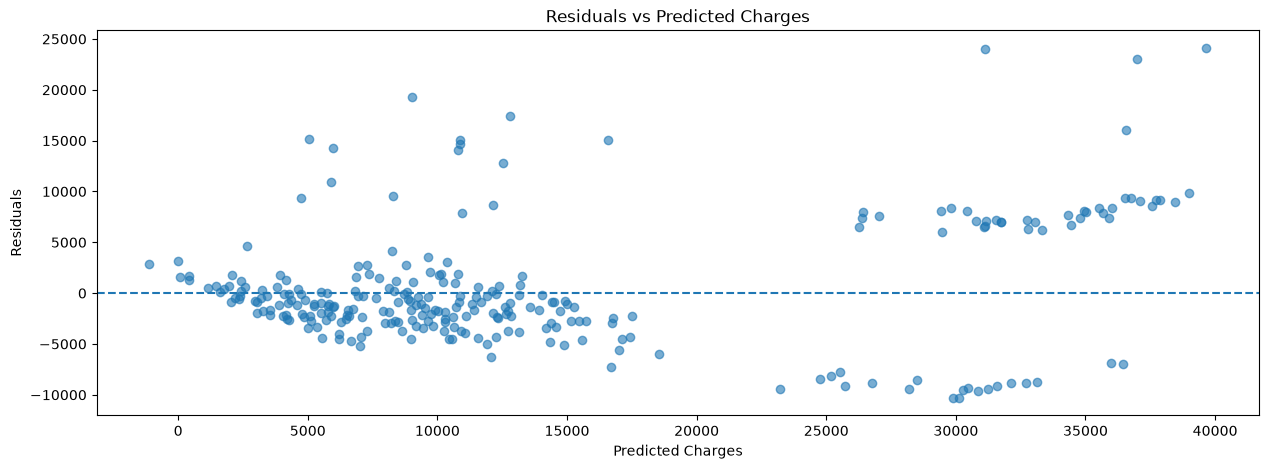

In [43]:

plt.figure(figsize=(15, 5))
plt.scatter(y_pred_linear, residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Charges")

plt.show()


##### Conclusion

- Linear Regression provides a strong improvement over the baseline model
- but its residual patterns suggest that a simple linear relationship may not capture all the patterns in medical insurance charges
- Further feature engineering and model experiments may improve its performance.


#### 6.3 - **Feature Engineering :** Smoker-BMI Interaction

Create an interaction feature between BMI and smoking status to allow the Linear Regression model to capture different BMI effects for smokers and non-smokers.


In [44]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

In [45]:
X_train_fe["smoker_bmi"] = ( X_train_fe["bmi"] * (X_train_fe["smoker"] == "yes").astype(int) )

In [46]:
X_test_fe["smoker_bmi"] = ( X_test_fe["bmi"] * (X_test_fe["smoker"] == "yes").astype(int) )

In [47]:
X_train_fe[["bmi", "smoker", "smoker_bmi"]].sample(5)

,bmi,smoker,smoker_bmi
1289,19.95,no,0.0
513,30.40,no,0.0
201,32.23,no,0.0
571,37.29,no,0.0
454,46.53,no,0.0


In [48]:
print("New training shape:", X_train_fe.shape)
print("New testing shape:", X_test_fe.shape)


New training shape: (1069, 7)
New testing shape: (268, 7)


#### 6.4 - Preprocessing Engineered Features

Extend the preprocessing transformations to include the new smoker-BMI interaction feature while keeping the original categorical encoding.

In [49]:
numeric_features_fe = numeric_features + ["smoker_bmi"]

In [50]:
preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_fe),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [51]:
X_train_fe_processed = preprocessor_fe.fit_transform(X_train_fe)
X_test_fe_processed = preprocessor_fe.transform(X_test_fe)

In [52]:
feature_names_fe = preprocessor_fe.get_feature_names_out()
print("Training shape:", X_train_fe_processed.shape)
print("Testing shape:", X_test_fe_processed.shape)

Training shape: (1069, 9)
Testing shape: (268, 9)


In [53]:
print(feature_names_fe)

['num__age' 'num__bmi' 'num__children' 'num__smoker_bmi' 'cat__sex_male'
 'cat__smoker_yes' 'cat__region_northwest' 'cat__region_southeast'
 'cat__region_southwest']



#### 6.5 - Linear Regression with Feature Engineering

Train a new Linear Regression model using the engineered features, including the smoker-BMI interaction.

Compare its performance with the original Linear Regression model to evaluate whether the new feature improves prediction quality.

In [54]:
linear_model_fe = LinearRegression()
linear_model_fe.fit(X_train_fe_processed, y_train)
y_pred_linear_fe = linear_model_fe.predict(X_test_fe_processed)

In [55]:
print("Engineered model bias:", linear_model_fe.intercept_)
print("Number of learned weights:", len(linear_model_fe.coef_))

Engineered model bias: 18272.849245849327
Number of learned weights: 9


* Now Evaluate the new model

In [56]:
fe_mae = mean_absolute_error(y_test, y_pred_linear_fe)
fe_mse = mean_squared_error(y_test, y_pred_linear_fe)
fe_rmse = np.sqrt(fe_mse)
fe_r2 = r2_score(y_test, y_pred_linear_fe)

In [57]:
feature_engineering_comparison = pd.DataFrame({
    "Model": [ "Original Linear Regression", "Linear Regression + smoker_bmi" ],
    
    "MAE": [linear_mae, fe_mae],
    "MSE": [linear_mse, fe_mse],
    "RMSE": [linear_rmse, fe_rmse],
    "R2": [linear_r2, fe_r2]
})

In [58]:
feature_engineering_comparison.round(4)

,Model,MAE,MSE,RMSE,R2
0,Original Linear Regression,4177.0456,3.547802e+07,5956.3429,0.8069
1,Linear Regression + smoker_bmi,2828.9737,2.091060e+07,4572.8112,0.8862


##### Observations - Smoker-BMI Interaction

- Adding the `smoker_bmi` interaction feature significantly **improved Linear Regression performance**.
- MAE decreased from approximately **$4,177** to **$2,829** (32.3% reduction).
- RMSE decreased from approximately **$5,956** to **$4,573** (23.2% reduction).
- R² increased from **0.8069** to **0.8862**.
- The interaction feature allows the model to represent different **BMI** relationships for **smokers** and **non-smokers**.

##### Conclusion

- The `smoker_bmi` feature provides useful additional information for predicting medical insurance charges
- The engineered Linear Regression model performs better than the original model on the evaluated test set.


#### 6.6 - Generalization Check

Compare training and testing performance to investigate whether the engineered Linear Regression model generalizes well to unseen observations.


In [59]:
y_pred_train_fe = linear_model_fe.predict(X_train_fe_processed)

In [60]:
train_mae_fe = mean_absolute_error(y_train, y_pred_train_fe)
train_rmse_fe = np.sqrt(mean_squared_error(y_train, y_pred_train_fe))
train_r2_fe = r2_score(y_train, y_pred_train_fe)

In [61]:
generalization_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [train_mae_fe, fe_mae],
    "RMSE": [train_rmse_fe, fe_rmse],
    "R2": [train_r2_fe, fe_r2]
})

generalization_results.round(4)


,Dataset,MAE,RMSE,R2
0,Training,2967.9824,4898.7002,0.8247
1,Testing,2828.9737,4572.8112,0.8862



#### Generalization Observations

- Training and testing performance are relatively close.
- The model achieves slightly lower MAE and RMSE on the test set.
- The test **R² (0.8862)** is higher than the training **R² (0.8247)**.
- There is **no clear indication of overfitting** in this train-test comparison.
- The difference may be due to the test samples being easier to predict than some training observations.

#### Conclusion

- The engineered Linear Regression model shows reasonable generalization on this particular split.
- Cross-validation will be used in later experiments to obtain a more reliable estimate of model performance.



#### 6.7 - Inspect Engineered Model Coefficients

Examine the learned coefficients of the engineered Linear Regression model to understand how the interaction feature contributes to predictions.


In [62]:
coefficients_fe = pd.DataFrame({
    "Feature": feature_names_fe,
    "Weight": linear_model_fe.coef_
})

In [63]:
coefficients_fe.sort_values( by="Weight",  key=abs, ascending=False )

,Feature,Weight
5,cat__smoker_yes,-21687.830077
3,num__smoker_bmi,18355.436758
0,num__age,3624.555493
7,cat__region_southeast,-895.669808
8,cat__region_southwest,-884.564628
2,num__children,680.722998
4,cat__sex_male,-647.366040
6,cat__region_northwest,-438.161448
1,num__bmi,75.564129



#### 6.8 - Residual Comparison

Compare the residual distributions of the original and engineered Linear Regression models to investigate how the interaction feature affects prediction errors.


In [64]:
residuals_original = y_test - y_pred_linear
residuals_fe = y_test - y_pred_linear_fe

In [65]:
residual_comparison = pd.DataFrame({
    "Model": ["Original Linear Regression","Linear Regression + smoker_bmi"],
    
    "Mean Residual": [
        residuals_original.mean(),
        residuals_fe.mean()
    ],
    "Minimum Residual": [
        residuals_original.min(),
        residuals_fe.min()
    ],
    "Maximum Residual": [
        residuals_original.max(),
        residuals_fe.max()
    ],
    "MAE": [linear_mae, fe_mae],
    "RMSE": [linear_rmse, fe_rmse]
})


In [66]:
residual_comparison.round(2)

,Model,Mean Residual,Minimum Residual,Maximum Residual,MAE,RMSE
0,Original Linear Regression,425.26,-10314.51,24111.22,4177.05,5956.34
1,Linear Regression + smoker_bmi,-44.37,-11083.69,20812.98,2828.97,4572.81


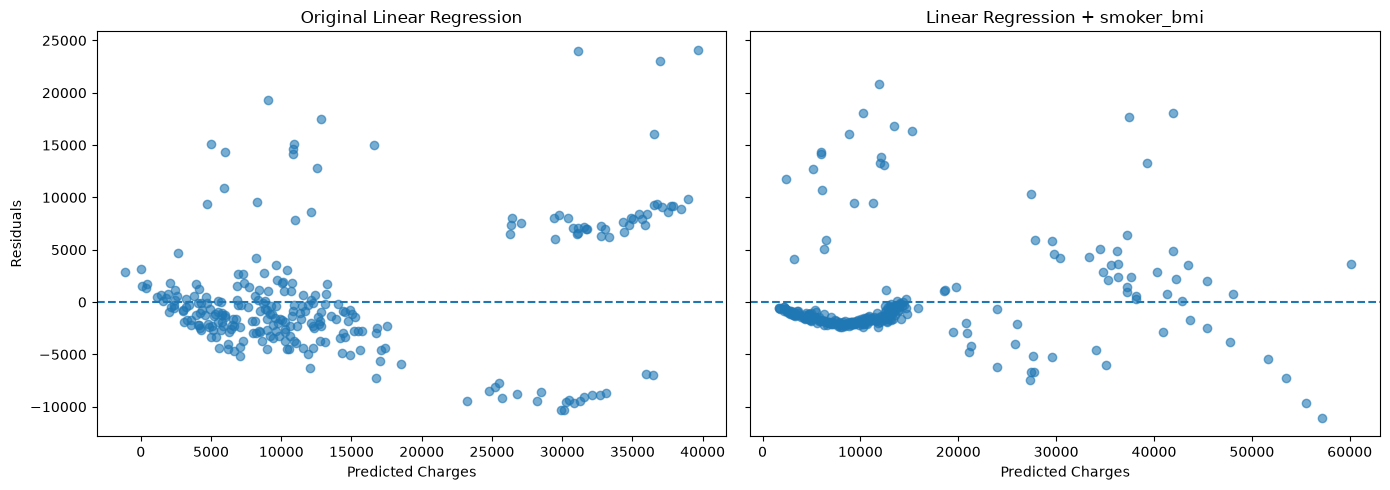

In [67]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Original model
axes[0].scatter(y_pred_linear, residuals_original, alpha=0.6)
axes[0].axhline(y=0, linestyle="--")
axes[0].set_title("Original Linear Regression")
axes[0].set_xlabel("Predicted Charges")
axes[0].set_ylabel("Residuals")

# Engineered model
axes[1].scatter(y_pred_linear_fe, residuals_fe, alpha=0.6)
axes[1].axhline(y=0, linestyle="--")
axes[1].set_title("Linear Regression + smoker_bmi")
axes[1].set_xlabel("Predicted Charges")

plt.tight_layout()
plt.show()



### Residual Analysis Conclusion

- The `smoker_bmi` interaction feature improved overall prediction performance.
- MAE decreased by approximately **32.3%**, while RMSE decreased by approximately **23.2%**.
- The mean residual moved closer to zero, indicating less average signed prediction bias on the test set.
- The largest positive residual decreased, while the largest negative residual became slightly more extreme.
- Residuals still show substantial errors at higher predicted charges, suggesting that the model does not capture all patterns in expensive insurance cases.

**Conclusion:** The interaction feature provides useful information and improves Linear Regression performance, although some prediction limitations remain.



### 7 - Cross-Validation

Use 5-Fold Cross-Validation to evaluate the original and engineered Linear Regression models across multiple training and validation splits.

The preprocessing and feature engineering steps are included in pipelines to prevent data leakage during validation.

In [68]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import KFold, cross_validate

In [69]:
def add_smoker_bmi(data):
    data = data.copy()
    data["smoker_bmi"] = ( data["bmi"] * (data["smoker"] == "yes").astype(int) )
    return data

In [70]:
preprocessor_original_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [71]:
preprocessor_interaction_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features + ["smoker_bmi"]),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [72]:
original_pipeline = Pipeline([
    ("preprocessing", preprocessor_original_cv),
    ("model", LinearRegression())
])

In [73]:
interaction_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("model", LinearRegression())
])

#### 7.1 - Run 5-Fold Cross-Validation

In [74]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [75]:
scoring = { "MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2" }

In [76]:
original_cv_results = cross_validate( original_pipeline, X_train, y_train, cv=cv, scoring=scoring )

In [77]:
interaction_cv_results = cross_validate( interaction_pipeline, X_train, y_train, cv=cv, scoring=scoring )

#### 7.2 — Compare Cross-Validation Results

In [78]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear Regression + smoker_bmi"
    ],
    "Mean MAE": [
        -original_cv_results["test_MAE"].mean(),
        -interaction_cv_results["test_MAE"].mean()
    ],
    "Mean RMSE": [
        -original_cv_results["test_RMSE"].mean(),
        -interaction_cv_results["test_RMSE"].mean()
    ],
    "Mean R2": [
        original_cv_results["test_R2"].mean(),
        interaction_cv_results["test_R2"].mean()
    ]
})


In [79]:
cv_comparison.round(4)

,Model,Mean MAE,Mean RMSE,Mean R2
0,Original Linear Regression,4221.9633,6123.6513,0.7228
1,Linear Regression + smoker_bmi,2992.7284,4943.0134,0.8188


### 7.3 -- Final observations: Interaction Feature

##### Individual Fold Results

Compare the performance of the original and engineered Linear Regression models in each validation fold.

This helps us determine whether the improvement from the `smoker_bmi` interaction feature is consistent across different data splits.

In [80]:
fold_comparison = pd.DataFrame({
    "Fold": range(1, 6),

    "Original MAE": -original_cv_results["test_MAE"],
    "Interaction MAE": -interaction_cv_results["test_MAE"],

    "Original RMSE": -original_cv_results["test_RMSE"],
    "Interaction RMSE": -interaction_cv_results["test_RMSE"],

    "Original R2": original_cv_results["test_R2"],
    "Interaction R2": interaction_cv_results["test_R2"]
})

fold_comparison.round(2)

,Fold,Original MAE,Interaction MAE,Original RMSE,Interaction RMSE,Original R2,Interaction R2
0,1,3872.83,2930.30,5846.90,4996.36,0.73,0.80
1,2,4174.15,2881.93,6003.92,4778.02,0.72,0.82
2,3,4193.93,2954.61,6130.97,4792.48,0.77,0.86
3,4,4467.57,3237.53,6239.26,5035.81,0.69,0.80
4,5,4401.34,2959.27,6397.21,5112.40,0.71,0.81


``Excellent!``  
This is a very good result, The engineered model (smoker_bmi) performed better in all five folds, not just on average.

In [81]:
cv_stability = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear Regression + smoker_bmi"
    ],

    "Mean MAE": [
        -original_cv_results["test_MAE"].mean(),
        -interaction_cv_results["test_MAE"].mean()
    ],

    "Std MAE": [
        original_cv_results["test_MAE"].std(),
        interaction_cv_results["test_MAE"].std()
    ],

    "Mean RMSE": [
        -original_cv_results["test_RMSE"].mean(),
        -interaction_cv_results["test_RMSE"].mean()
    ],

    "Std RMSE": [
        original_cv_results["test_RMSE"].std(),
        interaction_cv_results["test_RMSE"].std()
    ],

    "Mean R2": [
        original_cv_results["test_R2"].mean(),
        interaction_cv_results["test_R2"].mean()
    ],

    "Std R2": [
        original_cv_results["test_R2"].std(),
        interaction_cv_results["test_R2"].std()
    ]
})

cv_stability.round(4)

,Model,Mean MAE,Std MAE,Mean RMSE,Std RMSE,Mean R2,Std R2
0,Original Linear Regression,4221.9633,208.5490,6123.6513,189.3025,0.7228,0.0283
1,Linear Regression + smoker_bmi,2992.7284,125.4398,4943.0134,134.1854,0.8188,0.0227


##### Final Observations

The 5-Fold Cross-Validation results show that the Linear Regression model with the `smoker_bmi` interaction feature consistently outperforms the original Linear Regression model.

The engineered model achieved:

- **Lower MAE** in all five folds.
- **Lower RMSE** in all five folds.
- **Higher R²** in all five folds.

On average, **MAE decreased** by approximately **29.1%**, while **RMSE decreased** by approximately **19.3%**.

The standard deviations were also lower for the interaction model across all three evaluation metrics, indicating more consistent performance across the validation folds.

These results suggest that the interaction between BMI and smoking status helps the model capture additional relationships in the insurance data.

Therefore, we will keep the `smoker_bmi` interaction feature in the following experiments.

### 8 - Ridge Regression ( L2 Regularization )

In [82]:
from sklearn.linear_model import Ridge

#### 8.1 — Build Ridge Regression Pipeline

Ridge Regression applies L2 regularization by adding a penalty on large model coefficients.

We will use the same preprocessing and `smoker_bmi` interaction feature as our best Linear Regression model to make the comparison fair.

In [83]:
ridge_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("model", Ridge(alpha=1.0))
])

In [84]:
ridge_cv_results = cross_validate( ridge_pipeline, X_train, y_train, cv=cv, scoring=scoring )

In [85]:
ridge_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression + smoker_bmi", "Ridge Regression + smoker_bmi"
    ],

    "Mean MAE": [
        -interaction_cv_results["test_MAE"].mean(),
        -ridge_cv_results["test_MAE"].mean()
    ],

    "Mean RMSE": [
        -interaction_cv_results["test_RMSE"].mean(),
        -ridge_cv_results["test_RMSE"].mean()
    ],

    "Mean R2": [
        interaction_cv_results["test_R2"].mean(),
        ridge_cv_results["test_R2"].mean()
    ]
})

ridge_comparison.round(4)

,Model,Mean MAE,Mean RMSE,Mean R2
0,Linear Regression + smoker_bmi,2992.7284,4943.0134,0.8188
1,Ridge Regression + smoker_bmi,3000.2924,4952.6325,0.8181


#### 8.2 — Ridge Hyperparameter Tuning

The `alpha` parameter controls the strength of L2 regularization.

We will test different alpha values using 5-Fold Cross-Validation to identify the value that provides the best predictive performance.

We use MAE as our primary selection metric while also monitoring RMSE and R².

In [86]:
from sklearn.model_selection import GridSearchCV

In [87]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={  "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000] },
    scoring=scoring,
    cv=cv,
    refit="MAE"
)

ridge_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'MAE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation ti

In [88]:
ridge_alpha_results = pd.DataFrame({
    "Alpha": ridge_search.cv_results_["param_model__alpha"].astype(float),
    "Mean MAE": -ridge_search.cv_results_["mean_test_MAE"],
    "Mean RMSE": -ridge_search.cv_results_["mean_test_RMSE"],
    "Mean R2": ridge_search.cv_results_["mean_test_R2"]
})

ridge_alpha_results.sort_values("Mean MAE").round(4)

,Alpha,Mean MAE,Mean RMSE,Mean R2
2,0.100,2992.1186,4942.7850,0.8188
1,0.010,2992.6568,4942.9731,0.8188
0,0.001,2992.7212,4943.0092,0.8188
3,1.000,3000.2924,4952.6325,0.8181
4,10.000,3177.6866,5119.1423,0.8058
5,100.000,3625.9488,5376.6733,0.7865
6,1000.000,5513.4517,7495.1067,0.5878


##### Final Observations

GridSearchCV identified `alpha = 0.1` as the best Ridge regularization strength based on MAE.

The best Ridge model achieved:

- MAE: 2992.12
- RMSE: 4942.79
- R²: 0.8188

These results are almost identical to the original Linear Regression model with the `smoker_bmi` interaction feature.

Small alpha values produced very similar results, while stronger regularization significantly reduced performance.

This suggests that Ridge regularization does not provide a meaningful improvement for our current model and dataset.

We will keep the best Ridge result for comparison and move on to Lasso Regression.

### 9 - Lasso Regression (L1)

* Lasso Regression applies L1 regularization by adding a penalty based on the absolute values of model coefficients.

* We will use the same feature engineering and preprocessing pipeline to compare it fairly with our previous models.

In [89]:
from sklearn.linear_model import Lasso

In [90]:
lasso_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

In [91]:
lasso_cv_results = cross_validate(lasso_pipeline, X_train, y_train, cv=cv, scoring=scoring )

In [92]:
lasso_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression + smoker_bmi", "Best Ridge Regression", "Lasso Regression + smoker_bmi"
    ],

    "Mean MAE": [
        -interaction_cv_results["test_MAE"].mean(),
        -ridge_search.cv_results_["mean_test_MAE"][ridge_search.best_index_],
        -lasso_cv_results["test_MAE"].mean()
    ],

    "Mean RMSE": [
        -interaction_cv_results["test_RMSE"].mean(),
        -ridge_search.cv_results_["mean_test_RMSE"][ridge_search.best_index_],
        -lasso_cv_results["test_RMSE"].mean()
    ],

    "Mean R2": [
        interaction_cv_results["test_R2"].mean(),
        ridge_search.cv_results_["mean_test_R2"][ridge_search.best_index_],
        lasso_cv_results["test_R2"].mean()
    ]
})

lasso_comparison.round(4)

,Model,Mean MAE,Mean RMSE,Mean R2
0,Linear Regression + smoker_bmi,2992.7284,4943.0134,0.8188
1,Best Ridge Regression,2992.1186,4942.7850,0.8188
2,Lasso Regression + smoker_bmi,2992.7204,4942.9193,0.8188


#### 9.2 — Lasso Hyperparameter Tuning

The `alpha` parameter controls the strength of L1 regularization.

In [93]:
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={  "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000] },
    scoring=scoring,
    cv=cv,
    refit="MAE"
)

lasso_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=10000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'MAE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time

In [94]:
lasso_alpha_results = pd.DataFrame({
    "Alpha": lasso_search.cv_results_["param_model__alpha"].astype(float),
    "Mean MAE": -lasso_search.cv_results_["mean_test_MAE"],
    "Mean RMSE": -lasso_search.cv_results_["mean_test_RMSE"],
    "Mean R2": lasso_search.cv_results_["mean_test_R2"]
})

lasso_alpha_results.sort_values("Mean MAE").round(4)

,Alpha,Mean MAE,Mean RMSE,Mean R2
3,1.000,2992.7204,4942.9193,0.8188
2,0.100,2992.7276,4943.0005,0.8188
1,0.010,2992.7283,4943.0121,0.8188
0,0.001,2992.7284,4943.0133,0.8188
4,10.000,2995.7205,4945.5905,0.8186
5,100.000,3260.5897,5224.2678,0.7979
6,1000.000,3783.0129,5516.4826,0.7754


#### 9.3 — Inspect Lasso Coefficients

Lasso uses L1 regularization, which can shrink some feature coefficients exactly to zero.

In [95]:
best_lasso_model = lasso_search.best_estimator_

lasso_features = best_lasso_model.named_steps[ "preprocessing" ].get_feature_names_out()

lasso_weights = best_lasso_model.named_steps["model"].coef_

lasso_coefficients = pd.DataFrame({ "Feature": lasso_features, "Coefficient": lasso_weights })

lasso_coefficients["Absolute Coefficient"] = ( lasso_coefficients["Coefficient"].abs() )

lasso_coefficients["Selected"] = ( lasso_coefficients["Absolute Coefficient"] > 1e-8 )

lasso_coefficients.sort_values( "Absolute Coefficient", ascending=False ).round(4)

,Feature,Coefficient,Absolute Coefficient,Selected
5,cat__smoker_yes,-21464.8004,21464.8004,True
3,num__smoker_bmi,18266.4231,18266.4231,True
0,num__age,3623.3284,3623.3284,True
7,cat__region_southeast,-877.7592,877.7592,True
8,cat__region_southwest,-865.9092,865.9092,True
2,num__children,679.5299,679.5299,True
4,cat__sex_male,-640.8485,640.8485,True
6,cat__region_northwest,-420.7563,420.7563,True
1,num__bmi,82.4170,82.4170,True


##### Final Observations

The Lasso model with the best alpha (`1.0`) retained all nine features.

Although Lasso can perform feature selection by shrinking coefficients to exactly zero, no features were eliminated in this experiment.

The results indicate that the current features continue to contribute to the model under the selected regularization strength.

The predictive performance was almost identical to the original Linear Regression and Ridge models.

Therefore, Lasso did not provide a meaningful improvement in prediction performance or feature reduction for this dataset.

We will retain its results for the final model comparison.

### 10 - Improve preprocessing for Regularization

We already used StandardScaler on numerical features, but our One-Hot Encoded features remained on a 0/1 scale.

Ridge and Lasso penalize coefficients. If features have different scales, the regularization penalty can affect them differently.

#### 10.1 — Standardize All Processed Features

Ridge and Lasso are sensitive to feature scales because they penalize model coefficients.

Although our numerical features were already standardized, the one-hot encoded categorical features remained on a 0/1 scale.

We will apply an additional StandardScaler after preprocessing to standardize all processed features before regularization.

In [96]:
ridge_pipeline_scaled = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("scaling", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

lasso_pipeline_scaled = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("scaling", StandardScaler()),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

In [97]:
ridge_search_scaled = GridSearchCV(
    estimator=ridge_pipeline_scaled,
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    scoring=scoring,
    cv=cv,
    refit="MAE"
)

ridge_search_scaled.fit(X_train, y_train)

print("Best alpha:", ridge_search_scaled.best_params_)
print("Best MAE:", -ridge_search_scaled.best_score_)

Best alpha: {'model__alpha': 0.001}
Best MAE: 2992.7297707295716


In [98]:
lasso_search_scaled = GridSearchCV(
    estimator=lasso_pipeline_scaled,
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    scoring=scoring,
    cv=cv,
    refit="MAE"
)

lasso_search_scaled.fit(X_train, y_train)

print("Best alpha:", lasso_search_scaled.best_params_)
print("Best MAE:", -lasso_search_scaled.best_score_)

Best alpha: {'model__alpha': 0.001}
Best MAE: 2992.728548712418


* Final Model Comparison : 

In [99]:
regularization_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge (Best Original)",
        "Lasso (Best Original)",
        "Ridge (Scaled)",
        "Lasso (Scaled)"
    ],
    "Best Alpha": [
        None, 0.1, 1, 0.001, 0.001
    ],
    "Mean MAE": [
        2992.7284,
        2992.1186,
        2992.7204,
        2992.7298,
        2992.7285
    ]
})

regularization_results.sort_values("Mean MAE")

,Model,Best Alpha,Mean MAE
1,Ridge (Best Original),0.100,2992.1186
2,Lasso (Best Original),1.000,2992.7204
0,Linear Regression,NaN,2992.7284
4,Lasso (Scaled),0.001,2992.7285
3,Ridge (Scaled),0.001,2992.7298


### 11 - Decision Tree Regression

In [100]:
from sklearn.tree import DecisionTreeRegressor

In [101]:
tree_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("model", DecisionTreeRegressor(random_state=42))
])

tree_scores = cross_validate( tree_pipeline, X_train, y_train, cv=cv, scoring=scoring )

In [102]:
print("MAE:", -tree_scores["test_MAE"].mean())
print("RMSE:", -tree_scores["test_RMSE"].mean())
print("R2:", tree_scores["test_R2"].mean())

MAE: 3301.5454062533454
RMSE: 6747.09798756999
R2: 0.6630503014219378


#### Tune Tree Depth

In [103]:
tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid={ "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None] },
    scoring=scoring,
    cv=cv,
    refit="MAE"
)

tree_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'MAE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time fo

In [104]:
print("Best parameters:", tree_search.best_params_)
print("Best MAE:", -tree_search.best_score_)
print("Best RMSE:", -tree_search.cv_results_["mean_test_RMSE"][tree_search.best_index_])
print("Best R2:", tree_search.cv_results_["mean_test_R2"][tree_search.best_index_])

Best parameters: {'model__max_depth': 5}
Best MAE: 2731.38935547273
Best RMSE: 4820.311526338747
Best R2: 0.8258950289570584


#### Random Forest Regression

* Instead of relying on one decision tree, Random Forest combines predictions from many trees.

In [105]:
from sklearn.ensemble import RandomForestRegressor

In [106]:
forest_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("model", RandomForestRegressor( n_estimators=200, random_state=42, n_jobs=-1 ))
])

forest_scores = cross_validate( forest_pipeline, X_train, y_train, cv=cv, scoring=scoring )

In [107]:
print("MAE:", -forest_scores["test_MAE"].mean())
print("RMSE:", -forest_scores["test_RMSE"].mean())
print("R2:", forest_scores["test_R2"].mean())

MAE: 2769.8230458325565
RMSE: 4921.018944968908
R2: 0.8196473479111519


#### Tune Random Forest

In [108]:
forest_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid={
        "model__max_depth": [5, 8, 12, None],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [0.7, 1.0]
    },
    scoring=scoring,
    cv=cv,
    refit="MAE",
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [5, 8, ...], 'model__max_features': [0.7, 1.0], 'model__min_samples_leaf': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'MAE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls th

In [109]:
print("Best parameters:", forest_search.best_params_)
print("Best MAE:", -forest_search.best_score_)
print("Best RMSE:", -forest_search.cv_results_["mean_test_RMSE"][forest_search.best_index_])
print("Best R2:", forest_search.cv_results_["mean_test_R2"][forest_search.best_index_])

Best parameters: {'model__max_depth': 5, 'model__max_features': 1.0, 'model__min_samples_leaf': 4}
Best MAE: 2556.944784815575
Best RMSE: 4579.903774528253
Best R2: 0.8437034344078829


## Final Model Comparison

In [110]:
final_comparison = pd.DataFrame({
    "Model": [ "Linear Regression", "Ridge", "Lasso", "Decision Tree", "Random Forest" ],
    "MAE": [ 2992.7284, 2992.1186, 2992.7204, 2731.3894, 2556.9448 ],
    "RMSE": [ 4943.0134, 4942.7850, 4942.9193, 4820.3115, 4579.9038 ],
    "R2": [ 0.8188, 0.8188, 0.8188, 0.8259, 0.8437 ]
})

final_comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
4,Random Forest,2556.9448,4579.9038,0.8437
3,Decision Tree,2731.3894,4820.3115,0.8259
1,Ridge,2992.1186,4942.7850,0.8188
2,Lasso,2992.7204,4942.9193,0.8188
0,Linear Regression,2992.7284,4943.0134,0.8188


In [111]:
final_model = forest_search.best_estimator_

y_pred_final = final_model.predict(X_test)

print("Final Test MAE:", mean_absolute_error(y_test, y_pred_final))
print("Final Test RMSE:", mean_squared_error(y_test, y_pred_final) ** 0.5)
print("Final Test R2:", r2_score(y_test, y_pred_final))

Final Test MAE: 2413.39728047069
Final Test RMSE: 4260.410131965081
Final Test R2: 0.9012217932111836



### 12. Final Regression Models Conclusion

We compared five regression approaches using 5 fold Cross Validation:

- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree Regressor
- Random Forest Regressor

#### Key Findings

1. Feature engineering using `smoker_bmi` significantly improved the linear model.
2. Ridge and Lasso provided almost no additional improvement.
3. Decision Tree performed better after tuning `max_depth`.
4. Random Forest achieved the best cross-validation performance.

#### Selected Model

The optimized Random Forest was selected with:

- `n_estimators = 200`
- `max_depth = 5`
- `min_samples_leaf = 4`
- `max_features = 1.0`

#### Final Test Results

- MAE: $2,413.40
- RMSE: $4,260.41
- R²: 0.9012

#### Limitation

The test set was consulted during earlier feature engineering experiments.  
Therefore, its results should not be interpreted as a completely independent final evaluation.


### 13 - Residual Analysis

In [112]:
residuals = y_test - y_pred_final

residual_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_final,
    "Residual": residuals
})

residual_df.head()

,Actual,Predicted,Residual
899,8688.85885,11305.704627,-2616.845777
1063,5708.86700,7420.253314,-1711.386314
1255,11436.73815,11589.026764,-152.288614
298,38746.35510,39117.621950,-371.266850
237,4463.20510,6665.708117,-2202.503017


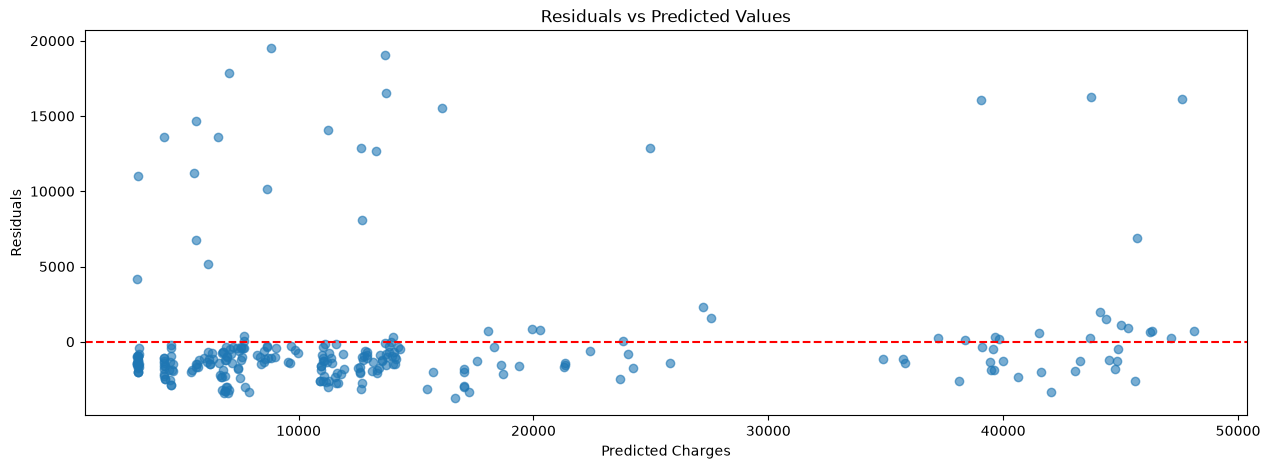

In [113]:
plt.figure(figsize=(15, 5))

plt.scatter(y_pred_final, residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

#### 14 - Actual vs Predicted

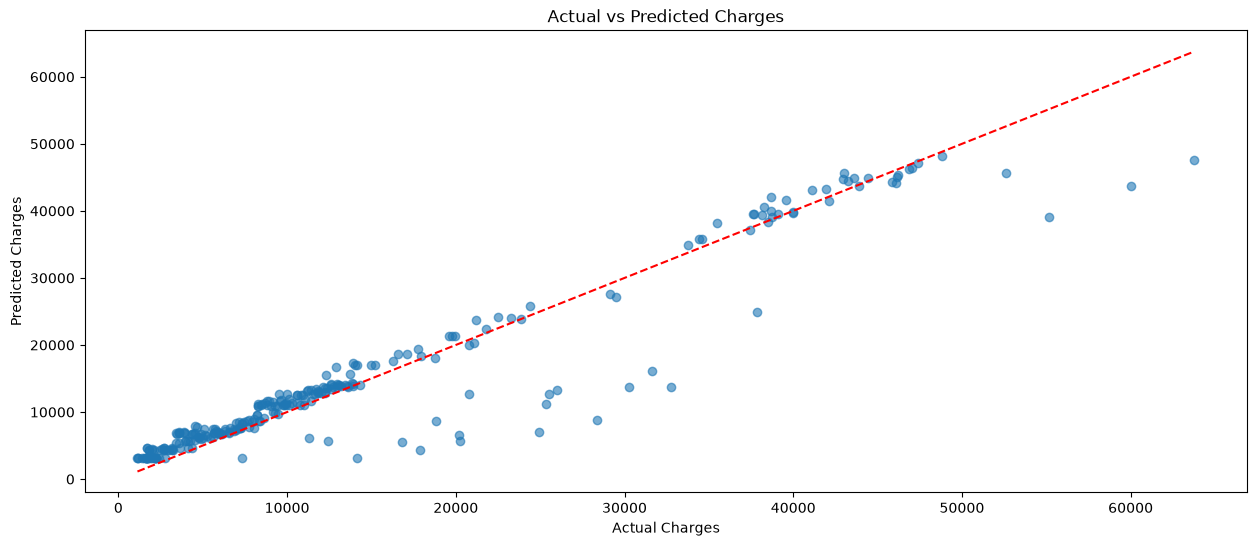

In [114]:
plt.figure(figsize=(15, 6))

plt.scatter(y_test, y_pred_final, alpha=0.6)

min_value = min(y_test.min(), y_pred_final.min())
max_value = max(y_test.max(), y_pred_final.max())

plt.plot( [min_value, max_value], [min_value, max_value], "r--" )
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")
plt.show()

### 14 - Feature Importance

In [115]:
feature_names = ( final_model.named_steps["preprocessing"].get_feature_names_out())

importances = pd.Series(
    final_model.named_steps["model"].feature_importances_,
    index=feature_names
).sort_values(ascending=True)

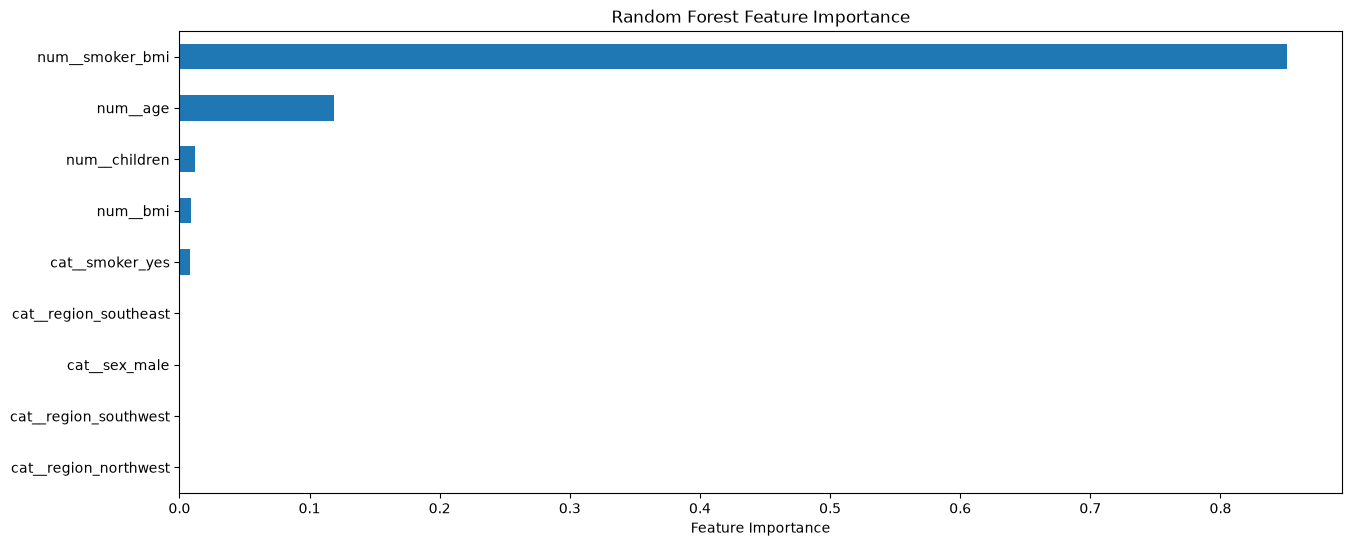

In [116]:
plt.figure(figsize=(15, 6))

importances.plot(kind="barh")
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.show()


## Final Project Conclusion

### Project Overview

The goal of this project was to predict individual medical insurance charges using Machine Learning regression models.

### Main Steps

1. Data cleaning and exploratory data analysis.
2. Data preprocessing and encoding.
3. Feature engineering using `smoker_bmi`.
4. Linear Regression and regularization (Ridge and Lasso).
5. Decision Tree and Random Forest.
6. Cross-validation and hyperparameter tuning.
7. Final evaluation and error analysis.

### Best Model: Optimized Random Forest

The optimized Random Forest achieved the following test results:

- MAE: $2,413.40
- RMSE: $4,260.41
- R²: 0.9012

### Key Findings

- The `smoker_bmi` interaction feature significantly improved model performance.
- Ridge and Lasso provided almost no additional improvement.
- The optimized Decision Tree outperformed the linear models.
- Random Forest achieved the best cross-validation and test results.
- Feature importance identified `smoker_bmi` and `age` as the dominant predictors.
- Residual analysis revealed some large prediction errors, particularly for expensive insurance cases.

### Limitations

The test set was consulted during earlier feature engineering experiments, so its evaluation is not completely independent.

Impurity-based feature importance also does not establish causal relationships.

### Final Conclusion

This project demonstrated a complete regression workflow, from data preparation and feature engineering to model comparison, hyperparameter tuning, and evaluation.

The optimized Random Forest was the strongest model among the approaches tested.


### ``Let's make our model usable``

In [117]:
final_model = forest_search.best_estimator_

In [118]:
import joblib

joblib.dump(final_model, "insurance_Cost_model.joblib")

['insurance_Cost_model.joblib']